In [1]:
!pip install -q -U timm

In [2]:
# =============================================================================
# CELL 0 — RESTORE THE 51 FINISHED RUNS FROM SESSION 1  (run this before cell 1)
# Needs the session-1 output attached as input (dataset or "Your Work").
# =============================================================================
import glob, os, shutil
def _depth_glob(pattern, max_depth=6):
    for d in range(1, max_depth + 1):
        hits = glob.glob("/kaggle/input/" + "*/" * (d - 1) + pattern)
        if hits: return hits
    return []
hits = _depth_glob("rev/runs")
assert hits, "Session-1 output not found: attach it with Add Input (it must contain the folder rev/runs)"
src = os.path.dirname(hits[0]); print("restoring from", src)
shutil.copytree(src, "/kaggle/working/rev", dirs_exist_ok=True)
n_npz = len(glob.glob("/kaggle/working/rev/runs/*.npz")); n_pt = len(glob.glob("/kaggle/working/rev/runs/*.pt"))
print(n_npz, "finished runs (.npz) |", n_pt, "checkpoints (.pt)")
assert n_npz >= 51, "expected 51 finished runs - check that the right output is attached"


restoring from /kaggle/input/datasets/sunidha/trustlung-starnet/rev
51 finished runs (.npz) | 32 checkpoints (.pt)


In [3]:
# =============================================================================
# CELL 1 — SETUP: data, class-stratified source-group split, all models, training
# ONE pipeline for every experiment: same seeds, same split, same recipe.
# Answers: R1#1, R1#2, R1#6, R1#8
# =============================================================================
import os, glob, json, random, hashlib, math, time, numpy as np, pandas as pd, torch
import torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageFile
import timm, torchvision.transforms as T
from sklearn.model_selection import train_test_split
T_START = time.time() if "T_START" not in globals() else T_START   # session start (for the time guard)
from sklearn.metrics import f1_score
ImageFile.LOAD_TRUNCATED_IMAGES = True; Image.MAX_IMAGE_PIXELS = None

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMG, BATCH, EPOCHS, NC = 224, 48, 15, 3
CLASSES = ["Benign", "ACA", "SCC"]
SEEDS = [42, 123, 456, 789, 1024]     # same 5 seeds as your Script B runs
CSV  = "/kaggle/input/datasets/gbatchkala/lc25000-clean-groups/lc25000_image_groups.csv"
ROOT = "/kaggle/input/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images/lung_colon_image_set"
LUNG, COLON = f"{ROOT}/lung_image_sets", f"{ROOT}/colon_image_sets"
EXT_ROOT = "/kaggle/input/datasets/abdullahhasansajjad/lunghist700/LungHist700_combined/data"   # external set
# ---- find the datasets automatically if the paths above differ in this account ----
def _find(path, pattern, check=None, max_depth=6):
    if os.path.exists(path): return path
    for d in range(1, max_depth + 1):
        for h in glob.glob("/kaggle/input/" + "*/" * (d - 1) + pattern):
            if check is None or check(h): print("found", pattern, "->", h); return h
    raise FileNotFoundError(f"{pattern} not found under /kaggle/input - attach the dataset")
CSV  = _find(CSV, "lc25000_image_groups.csv")
ROOT = _find(ROOT, "lung_colon_image_set", check=lambda h: os.path.isdir(f"{h}/lung_image_sets"))
EXT_ROOT = os.path.dirname(_find(f"{EXT_ROOT}/data.csv", "data.csv", check=lambda h: os.path.isdir(os.path.join(os.path.dirname(h), "images"))))
LUNG, COLON = f"{ROOT}/lung_image_sets", f"{ROOT}/colon_image_sets"
print("CSV:", CSV, "\nROOT:", ROOT, "\nEXT_ROOT:", EXT_ROOT)
OUT = "/kaggle/working/rev"
for d in ("runs", "splits", "ext"): os.makedirs(f"{OUT}/{d}", exist_ok=True)
LAB = {"lung_n": 0, "lung_aca": 1, "lung_scc": 2}

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

def sha256(fn):
    h = hashlib.sha256()
    with open(fn, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()

# ---------- one table: path, label, source group, for ALL lung images ----------
def load_table():
    disk = {os.path.basename(p): p for s in LAB for p in glob.glob(f"{LUNG}/{s}/*.jpeg")}
    df = pd.read_csv(CSV); df = df[df["tissue"].str.lower() == "lung"].copy()
    df["path"]  = df["filename"].apply(lambda f: disk.get(os.path.basename(str(f))))
    df["y"]     = df["label"].astype(str).str.lower().str.strip().map(LAB)
    df["group"] = df["group_id"].astype(str)
    df = df.dropna(subset=["path", "y"]).reset_index(drop=True); df["y"] = df["y"].astype(int)
    assert len(df) == len(disk), f"CSV matched {len(df)} of {len(disk)} images"
    assert (df.groupby("group")["y"].nunique() == 1).all(), "a group has mixed labels"
    return df

DF = load_table()
print("images", len(DF), "| source groups", DF.group.nunique())
print("groups per class:", DF.groupby("y").group.nunique().to_dict(), "(expected 250 each if 750 originals)")
print("images per group:", DF.groupby("group").size().describe().round(1).to_dict())

# ---------- splits 70/15/15, same image pool for both protocols ----------
def make_split(protocol, split_seed):
    """LEAKY : stratified random split of images.
       HONEST: source-group-disjoint, stratified by class at GROUP level."""
    d = DF.copy()
    if protocol == "LEAKY":
        tr, tmp = train_test_split(d.index, test_size=.30, stratify=d.y, random_state=split_seed)
        va, te  = train_test_split(tmp, test_size=.50, stratify=d.y[tmp], random_state=split_seed)
    else:
        g = d.groupby("group").y.first()
        gtr, gtmp = train_test_split(g.index, test_size=.30, stratify=g, random_state=split_seed)
        gva, gte  = train_test_split(gtmp, test_size=.50, stratify=g[gtmp], random_state=split_seed)
        tr, va, te = (d.index[d.group.isin(x)] for x in (gtr, gva, gte))
        assert not (set(d.group[tr]) & set(d.group[te])) and not (set(d.group[va]) & set(d.group[te]))
    d["split"] = ""; d.loc[tr, "split"] = "train"; d.loc[va, "split"] = "val"; d.loc[te, "split"] = "test"
    fn = f"{OUT}/splits/{protocol}_split{split_seed}.csv"
    if not os.path.exists(fn): d[["filename", "y", "group", "split"]].to_csv(fn, index=False)
    return d

# ---------- data ----------
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
TF_TR = T.Compose([T.Resize((IMG, IMG)), T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.ToTensor(), T.Normalize(MEAN, STD)])
TF_TE = T.Compose([T.Resize((IMG, IMG)), T.ToTensor(), T.Normalize(MEAN, STD)])

class DS(Dataset):
    def __init__(s, P, L, tf, pre=None): s.P, s.L, s.tf, s.pre = list(P), list(L), tf, pre
    def __len__(s): return len(s.P)
    def __getitem__(s, i):
        img = Image.open(s.P[i]).convert("RGB")      # fail loudly, no silent black images
        if s.pre is not None: img = s.pre(img)
        return s.tf(img), int(s.L[i])

def loader(P, L, train, seed, pre=None):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(DS(P, L, TF_TR if train else TF_TE, pre), batch_size=BATCH, shuffle=train,
                      num_workers=4, pin_memory=True, generator=g,
                      worker_init_fn=lambda w: np.random.seed(seed + w))

# ---------- models ----------
def bb(tid): return timm.create_model(tid, pretrained=True, num_classes=0, global_pool="avg")

class TrustLung(nn.Module):
    """Original TrustLung + switches (same code path for every variant).
       variant: full | no_global | no_local | concat | no_hier | softmax | mcd
       'mcd' = softmax head with dropout (p=0.2) before the heads -> MC-dropout baseline (R1#4)"""
    def __init__(s, variant="full", p_drop=0.2):
        super().__init__(); s.v = variant; d = 256
        s.use_g, s.use_l = variant != "no_global", variant != "no_local"
        if s.use_g: s.g = bb("efficientvit_m3.r224_in1k"); s.pg = nn.Linear(s.g.num_features, d)
        if s.use_l: s.l = bb("starnet_s1"); s.pl = nn.Linear(s.l.num_features, d)
        fd = 2*d if variant == "concat" else d
        if s.use_g and s.use_l and variant != "concat": s.gate = nn.Sequential(nn.Linear(2*d, d), nn.Sigmoid())
        s.bm = nn.Linear(fd, 2); s.sub = nn.Linear(fd, 2); s.evi = nn.Linear(fd, NC)
        s.evidential, s.hier = variant not in ("softmax", "mcd"), variant != "no_hier"
        s.drop = nn.Dropout(p_drop) if variant == "mcd" else nn.Identity()
    def features(s, x):
        if not s.use_g: return s.pl(s.l(x))
        if not s.use_l: return s.pg(s.g(x))
        g, l = s.pg(s.g(x)), s.pl(s.l(x))
        if s.v == "concat": return torch.cat([g, l], 1)
        z = s.gate(torch.cat([g, l], 1)); return z*g + (1-z)*l
    def heads(s, f):
        f = s.drop(f)
        with torch.autocast(device_type="cuda", enabled=False):     # fp32 head: no fp16 overflow -> no NaN
            h = s.evi(f.float()); h = F.softplus(h) if s.evidential else h
        return s.bm(f), s.sub(f), h
    def forward(s, x): return s.heads(s.features(x))

@torch.no_grad()
def mc_predict(model, dl, T=30, seed=0):
    """MC dropout: backbone features once, then T stochastic passes of dropout + head.
       Returns mean prob, predictive entropy, mutual information (epistemic part)."""
    torch.manual_seed(seed); model.eval(); model.drop.train(); P = []
    for x, _ in dl:
        x = x.to(DEVICE)
        with torch.amp.autocast("cuda", enabled=DEVICE == "cuda"): f = model.features(x).float()
        P.append(torch.stack([F.softmax(model.heads(f)[2].float(), 1) for _ in range(T)]).cpu())
    model.drop.eval(); P = torch.cat(P, 1).numpy()                       # T x N x K
    ent = lambda q: -(q*np.log(np.clip(q, 1e-12, 1))).sum(-1)
    return pm, H, MI

BASELINES = {"resnet50": ("resnet50.tv_in1k", 3e-4), "effb0": ("efficientnet_b0.ra_in1k", 3e-4),
             "vit_s": ("deit_small_patch16_224.fb_in1k", 1e-4)}
ABLATIONS = ["no_global", "no_local", "concat", "no_hier", "softmax"]
NAMES = {"trustlung": "TrustLung", "resnet50": "ResNet-50", "effb0": "EfficientNet-B0", "vit_s": "ViT-S (DeiT-S)",
         **{f"tl_{a}": f"TrustLung − {a}" for a in ABLATIONS}, "tl_mcd": "TrustLung (softmax + MC dropout)"}

def build(name):
    """returns model, lr, kind  (kind: 'tl' for TrustLung family, 'base' for plain classifiers)"""
    if name == "trustlung": return TrustLung("full"), 3e-4, "tl"
    if name.startswith("tl_"): return TrustLung(name[3:]), 3e-4, "tl"
    tid, lr = BASELINES[name]; return timm.create_model(tid, pretrained=True, num_classes=NC), lr, "base"

def evi_parts(evi):
    evi = torch.nan_to_num(evi.float(), nan=0.0, posinf=1e4, neginf=0.0).clamp(min=0)
    a = evi + 1; S = a.sum(1, keepdim=True); return a, S

def step(model, kind, x, y):
    """returns loss, prob, uncertainty  (evidential: K/S ; softmax: normalised entropy)"""
    if kind == "tl":
        lb, lsub, h = model(x)
        if model.evidential:
            a, S = evi_parts(h); p = a/S; u = (NC/S).squeeze(1); loss = evi_loss(h, y)
        else:
            p = F.softmax(h.float(), 1); u = -(p*p.clamp_min(1e-12).log()).sum(1)/math.log(NC); loss = F.cross_entropy(h.float(), y)
        if model.hier:
            m = y > 0; loss = loss + 0.5*F.cross_entropy(lb.float(), m.long())
            if m.any(): loss = loss + 0.5*F.cross_entropy(lsub[m].float(), y[m]-1)
    else:
        z = model(x).float(); p = F.softmax(z, 1); loss = F.cross_entropy(z, y)
        u = -(p*p.clamp_min(1e-12).log()).sum(1)/math.log(NC)
    return loss, p, u

def run_epoch(model, kind, dl, opt=None, scaler=None):
    train = opt is not None; model.train(train); P, U, Y = [], [], []
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=DEVICE == "cuda"):
                loss, p, u = step(model, kind, x, y)
            if train: opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            P.append(p.detach().float().cpu()); U.append(u.detach().float().cpu()); Y.append(y.cpu())
    return torch.cat(P).numpy(), torch.cat(U).numpy(), torch.cat(Y).numpy()

def tag_of(name, protocol, split_seed, init_seed): return f"{name}_{protocol}_split{split_seed}_init{init_seed}"

def train_eval(name, protocol, split_seed, init_seed):
    """Train one model; save checkpoint + val/test predictions with group IDs. Skips finished runs."""
    tag = tag_of(name, protocol, split_seed, init_seed); fn = f"{OUT}/runs/{tag}.npz"
    if os.path.exists(fn): print("skip (done):", tag); return fn
    t0 = time.time(); d = make_split(protocol, split_seed); part = {k: d[d.split == k] for k in ("train", "val", "test")}
    seed_all(init_seed)
    tr = loader(part["train"].path, part["train"].y, True, init_seed)
    va = loader(part["val"].path, part["val"].y, False, init_seed)
    te = loader(part["test"].path, part["test"].y, False, init_seed)
    model, lr, kind = build(name); model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS); scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
    best, ck = -1, f"{OUT}/runs/{tag}.pt"
    for ep in range(EPOCHS):
        run_epoch(model, kind, tr, opt, scaler); sch.step()
        pv, _, yv = run_epoch(model, kind, va); f1 = f1_score(yv, pv.argmax(1), average="macro")
        if not np.isfinite(pv).all(): print("  !! NaN in validation outputs")
        if f1 > best: best = f1; torch.save(model.state_dict(), ck)
        print(f"  [{tag}] ep{ep+1}/{EPOCHS} val macroF1 {f1:.4f} ({time.time()-t0:.0f}s)", flush=True)
    model.load_state_dict(torch.load(ck, map_location=DEVICE))
    pv, uv, yv = run_epoch(model, kind, va); pt, ut, yt = run_epoch(model, kind, te)
    assert np.isfinite(pt).all(), "NaN in test outputs"
    extra = {}
    if name == "tl_mcd":                                   # MC-dropout predictions (T = 30 passes)
        for k, dl in (("val", va), ("test", te)):
            pm, H, MI = mc_predict(model, dl, T=30, seed=init_seed)
            extra.update({f"{k}_prob_mc": pm, f"{k}_mc_entropy": H, f"{k}_mc_mi": MI})
    cfg = dict(model=name, protocol=protocol, split_seed=split_seed, init_seed=init_seed, lr=lr, epochs=EPOCHS,
               batch=BATCH, img=IMG, optimizer="AdamW wd=1e-4", schedule="cosine", select="best val macro-F1",
               augment="resize224 + h/v flip", torch=torch.__version__, timm=timm.__version__)
    json.dump(cfg, open(f"{OUT}/runs/{tag}.json", "w"), indent=1)
    np.savez(fn, **extra, val_prob=pv, val_unc=uv, val_y=yv, val_group=part["val"].group.values,
             test_prob=pt, test_unc=ut, test_y=yt, test_group=part["test"].group.values,
             test_file=part["test"].filename.values, n_params=sum(p.numel() for p in model.parameters()))
    print(f"==> {tag}: TEST acc {(pt.argmax(1) == yt).mean():.4f}  [{(time.time()-t0)/60:.1f} min]")
    if protocol == "LEAKY" and os.path.exists(ck): os.remove(ck)   # leaky checkpoints are not needed later
    del model, opt; torch.cuda.empty_cache(); return fn


CSV: /kaggle/input/datasets/gbatchkala/lc25000-clean-groups/lc25000_image_groups.csv 
ROOT: /kaggle/input/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images/lung_colon_image_set 
EXT_ROOT: /kaggle/input/datasets/abdullahhasansajjad/lunghist700/LungHist700_combined/data
images 15000 | source groups 740
groups per class: {0: 249, 1: 243, 2: 248} (expected 250 each if 750 originals)
images per group: {'count': 740.0, 'mean': 20.3, 'std': 5.3, 'min': 3.0, '25%': 17.0, '50%': 20.0, '75%': 23.0, 'max': 46.0}


group-size counts: {3: 1, 7: 2, 8: 1, 9: 3, 10: 2, 11: 5, 12: 16, 13: 19, 14: 39, 15: 38, 16: 49, 17: 38, 18: 76, 19: 50, 20: 62, 21: 77, 22: 45, 23: 51, 24: 36, 25: 32, 26: 25, 27: 21, 28: 18, 29: 7, 30: 5, 31: 2, 32: 6, 33: 3, 37: 1, 38: 2, 39: 1, 40: 1, 43: 1, 44: 2, 45: 2, 46: 1} | modal size 21
groups: 740 | implied originals if every group = k x 21 images: 751
groups whose size is not 21: 663 -> (see group_audit.csv)


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

CNN cosine: nearest SAME-group neighbour median 0.970 | nearest OTHER-group median 0.877 | threshold TAU (5th pct of same-group) = 0.918

odd-size groups (first 20):
 group  label  n_images  expected_originals  components_cnn  components_phash  min_within_cos
  912      0        46                   2               3                12        0.665187
  569      1        45                   2              18                 9        0.411301
 1033      2        45                   2               1                20        0.675404
  797      0        44                   2               1                 7        0.678425
 1005      2        44                   2               2                14        0.649339
  530      1        43                   2               2                15        0.534117
  524      1        40                   2               6                11        0.585475
  554      1        39                   2               3                14        0.646

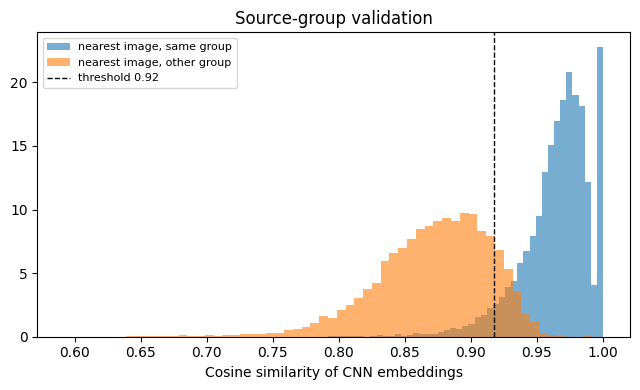


    PAPER SENTENCE (fill from the numbers above):
    "The grouping file assigns the 15000 lung images to 740 source groups. 77 groups contain
    21 images, consistent with one original and its augmentations, and 663 contain a multiple of 21
    images; the similarity analysis showed that these hold <X> distinct originals each, which explains the difference
    from the 750 originals reported for LC25000. Same-group nearest neighbours had a median embedding similarity of
    0.97 versus 0.88 across groups, and 2 cross-group pairs were near-identical
    (listed in Supplementary File S1)." -> if cross-group pairs exist, merge those groups and re-run (see MERGE below).


In [4]:
# (wrapped in try/except so an error here does not stop 'Save & Run All')
try:

    from scipy.fft import dct
    from scipy.sparse.csgraph import connected_components
    from concurrent.futures import ThreadPoolExecutor
    import matplotlib.pyplot as plt

    # ---------- Step 1: sizes ----------
    size = DF.groupby("group").size(); modal = int(size.mode()[0])
    print("group-size counts:", size.value_counts().sort_index().to_dict(), "| modal size", modal)
    implied = int(np.round(size / modal).sum())
    odd = size[size != modal]
    print(f"groups: {len(size)} | implied originals if every group = k x {modal} images: {implied}")
    print(f"groups whose size is not {modal}: {len(odd)} -> {odd.to_dict() if len(odd) < 30 else '(see group_audit.csv)'}")

    # ---------- Step 2a: pHash (8 dihedral views) ----------
    def phash_bits(img, hs=8, hi=32):
        a = np.asarray(img.convert("L").resize((hi, hi), Image.Resampling.LANCZOS), dtype=np.float32)
        c = dct(dct(a, axis=0, norm="ortho"), axis=1, norm="ortho")[:hs, :hs]
        return np.packbits((c > np.median(c)).ravel())
    def views8(im):
        out = []
        for k in range(4): r = im.rotate(90*k); out += [r, r.transpose(Image.Transpose.FLIP_LEFT_RIGHT)]
        return out
    def hashes_for(path): return np.stack([phash_bits(v) for v in views8(Image.open(path).convert("RGB"))])
    with ThreadPoolExecutor(8) as ex: H = np.stack(list(ex.map(hashes_for, DF.path)))        # N x 8 x 8 bytes
    POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
    def ham_to(i, idx):            # min Hamming distance (over 8 views of i) to the base view of images idx
        return POP[np.bitwise_xor(H[i][:, None, :], H[idx, 0][None])].sum(-1).min(0).astype(int)

    # ---------- Step 2b: CNN embeddings ----------
    emb_model = timm.create_model("efficientnet_b0.ra_in1k", pretrained=True, num_classes=0).to(DEVICE).eval()
  
    # nearest neighbour inside own group vs in other groups (full dataset, on GPU)
    nn_same, nn_other, nn_other_idx = [], [], []
    for i0 in range(0, len(DF), 512):
        S = E[i0:i0+512] @ E.T; rows = torch.arange(i0, min(i0+512, len(DF)), device=DEVICE)
        S[torch.arange(len(rows)), rows] = -2                                   # ignore self
        same = G_t[rows][:, None] == G_t[None]
        nn_same.append(torch.where(same, S, torch.full_like(S, -2)).max(1).values.cpu())
        v, j = torch.where(~same, S, torch.full_like(S, -2)).max(1); nn_other.append(v.cpu()); nn_other_idx.append(j.cpu())
    nn_same, nn_other, nn_other_idx = (torch.cat(a).numpy() for a in (nn_same, nn_other, nn_other_idx))
    normal = DF.group.map(size).values == modal
    TAU = float(np.percentile(nn_same[normal], 5))          # 95% of images have a same-group neighbour above this
    print(f"CNN cosine: nearest SAME-group neighbour median {np.median(nn_same):.3f} | nearest OTHER-group median "
          f"{np.median(nn_other):.3f} | threshold TAU (5th pct of same-group) = {TAU:.3f}")

    # ---------- Step 3: distinct originals inside every group ----------
    audit = []
    for g_, idx in DF.groupby("group").indices.items():
        Ei = E[idx]; A_cnn = (Ei @ Ei.T >= TAU).cpu().numpy()
        D = np.stack([ham_to(i, idx) for i in idx]); A_ph = D <= 10
        n_cnn = connected_components(A_cnn, directed=False)[0]; n_ph = connected_components(A_ph | A_ph.T, directed=False)[0]
        audit.append(dict(group=g_, label=int(DF.y[idx[0]]), n_images=len(idx), expected_originals=round(len(idx)/modal),
                          components_cnn=n_cnn, components_phash=n_ph, min_within_cos=float((Ei @ Ei.T).min())))
    audit = pd.DataFrame(audit).sort_values("n_images", ascending=False); audit.to_csv(f"{OUT}/group_audit.csv", index=False)
    oddA = audit[audit.n_images != modal]
    print("\nodd-size groups (first 20):\n", oddA.head(20).to_string(index=False))
    print(f"\nestimated distinct originals (sum of CNN components, capped by size/{modal}): "
          f"{int(np.minimum(audit.components_cnn, np.ceil(audit.n_images/modal)).sum())}")

    # ---------- Step 4: near-identical pairs across DIFFERENT groups ----------
    cand = np.where(nn_other >= max(TAU, np.median(nn_same)))[0]
    pairs = []
    for i in cand:
        j = int(nn_other_idx[i]); d = int(ham_to(i, np.array([j]))[0])
        pairs.append((DF.filename[i], DF.filename[j], grp[i], grp[j], int(DF.y[i]), int(DF.y[j]), float(nn_other[i]), d))
    pairs = pd.DataFrame(pairs, columns=["file_a", "file_b", "group_a", "group_b", "label_a", "label_b", "cnn_cos", "phash_bits"])
    pairs.to_csv(f"{OUT}/cross_group_pairs.csv", index=False)
    exact = (pairs.phash_bits <= 6).sum() if len(pairs) else 0
    print(f"images whose nearest OTHER-group image is as similar as a typical same-group image: {len(cand)} "
          f"({len(cand)/len(DF)*100:.2f}%) | of these, pHash near-identical (<=6 bits): {exact}")
    print("group pairs involved:", pairs[["group_a", "group_b"]].apply(lambda r: tuple(sorted(r)), axis=1).nunique() if len(pairs) else 0)

    plt.figure(figsize=(6.5, 4))
    plt.hist(nn_same, bins=60, alpha=.6, density=True, label="nearest image, same group")
    plt.hist(nn_other, bins=60, alpha=.6, density=True, label="nearest image, other group")
    plt.axvline(TAU, color="k", ls="--", lw=1, label=f"threshold {TAU:.2f}")
    plt.xlabel("Cosine similarity of CNN embeddings"); plt.legend(fontsize=8); plt.title("Source-group validation")
    plt.tight_layout(); plt.savefig(f"{OUT}/fig_group_validation.png", dpi=300); plt.show()

    print(f"""
    PAPER SENTENCE (fill from the numbers above):
    "The grouping file assigns the {len(DF)} lung images to {len(size)} source groups. {int((size == modal).sum())} groups contain
    {modal} images, consistent with one original and its augmentations, and {len(odd)} contain a multiple of {modal}
    images; the similarity analysis showed that these hold <X> distinct originals each, which explains the difference
    from the 750 originals reported for LC25000. Same-group nearest neighbours had a median embedding similarity of
    {np.median(nn_same):.2f} versus {np.median(nn_other):.2f} across groups, and {exact} cross-group pairs were near-identical
    (listed in Supplementary File S1)." -> if cross-group pairs exist, merge those groups and re-run (see MERGE below).""")

    # ---------- optional: merge groups that share near-identical images, then re-run cells 1-3 ----------
    MERGE = False
    if MERGE and len(pairs):
        from scipy.sparse import coo_matrix
        ex = pairs[pairs.phash_bits <= 6]; ug = pd.Index(sorted(set(grp)))
        a, b = ug.get_indexer(ex.group_a), ug.get_indexer(ex.group_b)
        n, lab = connected_components(coo_matrix((np.ones(len(a)), (a, b)), shape=(len(ug),)*2), directed=False)
        newmap = {g_: f"m{lab[k]}" for k, g_ in enumerate(ug)}
        out = pd.read_csv(CSV); out["group_id"] = out.group_id.astype(str).map(newmap).fillna(out.group_id.astype(str))
        out.to_csv(f"{OUT}/lc25000_image_groups_merged.csv", index=False)
        print(f"merged groups: {len(ug)} -> {n}. Set CSV = '{OUT}/lc25000_image_groups_merged.csv' in cell 1 and run again.")

except Exception as _e:
    import traceback; traceback.print_exc()
    print('>>> CELL 2 (group check) FAILED - the notebook continues; send me the error above')


In [5]:
# =============================================================================
# CELL 3 — TRAINING RUNS  (resumable: finished runs are skipped; run again after a
# Kaggle stop. Attach the previous output and copy rev/ back to /kaggle/working first.)
# ~8-12 min per run on a T4. Turn on blocks in priority order.
# =============================================================================
BLOCKS = {
    "A_main":      True,   # TrustLung LEAKY + HONEST, 5 seeds          -> R1#2, R1#3   (10 runs)
    "B_baselines": True,   # ResNet-50, EffNet-B0, ViT-S, both splits   -> R1#6, R2     (30 runs)
    "C_ablation":  True,   # 5 TrustLung variants, HONEST, 5 seeds      -> R1#6         (25 runs)
    "D_variance":  True,   # split-only vs init-only variation + ensemble -> R1#4, R1#8 (8 runs)
    "E_mcdropout": True,   # TrustLung softmax + MC dropout, HONEST     -> R1#4         (5 runs)
}
jobs = []
if BLOCKS["A_main"]:      jobs += [("trustlung", p, s, s) for s in SEEDS for p in ("LEAKY", "HONEST")]
if BLOCKS["B_baselines"]: jobs += [(m, p, s, s) for s in SEEDS for m in BASELINES for p in ("LEAKY", "HONEST")]
if BLOCKS["C_ablation"]:  jobs += [(f"tl_{a}", "HONEST", s, s) for s in SEEDS for a in ABLATIONS]
if BLOCKS["D_variance"]:
    s0 = SEEDS[0]
    jobs += [("trustlung", "HONEST", s0, s) for s in SEEDS[1:]] + [("trustlung", "HONEST", s, s0) for s in SEEDS[1:]]
if BLOCKS["E_mcdropout"]: jobs += [("tl_mcd", "HONEST", s, s) for s in SEEDS]
todo = [j for j in jobs if not os.path.exists(f"{OUT}/runs/{tag_of(*j)}.npz")]
print(f"{len(jobs)} runs planned, {len(jobs)-len(todo)} done, {len(todo)} to run")
for j in todo:
    used = (time.time() - T_START) / 3600
    if used + RUN_H > LIMIT_H:
        print(f"TIME GUARD: {used:.1f} h used - stopping so this version finishes and saves its files. "
              f"Run the notebook again to continue ({len([t for t in todo if not os.path.exists(f'{OUT}/runs/{tag_of(*t)}.npz')])} runs left)."); break
    train_eval(*j)

files = [CSV] + sorted(glob.glob(f"{OUT}/splits/*.csv"))
json.dump({os.path.basename(f): sha256(f) for f in files}, open(f"{OUT}/checksums.json", "w"), indent=1)
print("checksums saved")


78 runs planned, 51 done, 27 to run


model.safetensors: reconstructing file:   0%|          |  0.00B / 27.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Unexpected keys (head.bn.num_batches_tracked, head.bn.bias, head.bn.running_mean, head.bn.running_var, head.bn.weight) found while loading pretrained weights. This may be expected if model is being adapted.


  [tl_no_local_HONEST_split456_init456] ep1/15 val macroF1 0.9724 (58s)
  [tl_no_local_HONEST_split456_init456] ep2/15 val macroF1 0.9350 (111s)
  [tl_no_local_HONEST_split456_init456] ep3/15 val macroF1 0.9646 (163s)
  [tl_no_local_HONEST_split456_init456] ep4/15 val macroF1 0.9707 (216s)
  [tl_no_local_HONEST_split456_init456] ep5/15 val macroF1 0.9612 (269s)
  [tl_no_local_HONEST_split456_init456] ep6/15 val macroF1 0.9789 (322s)
  [tl_no_local_HONEST_split456_init456] ep7/15 val macroF1 0.9668 (374s)
  [tl_no_local_HONEST_split456_init456] ep8/15 val macroF1 0.9629 (427s)
  [tl_no_local_HONEST_split456_init456] ep9/15 val macroF1 0.9750 (479s)
  [tl_no_local_HONEST_split456_init456] ep10/15 val macroF1 0.9707 (531s)
  [tl_no_local_HONEST_split456_init456] ep11/15 val macroF1 0.9711 (584s)
  [tl_no_local_HONEST_split456_init456] ep12/15 val macroF1 0.9707 (636s)
  [tl_no_local_HONEST_split456_init456] ep13/15 val macroF1 0.9715 (688s)
  [tl_no_local_HONEST_split456_init456] ep14/15 

Unexpected keys (head.bn.num_batches_tracked, head.bn.bias, head.bn.running_mean, head.bn.running_var, head.bn.weight) found while loading pretrained weights. This may be expected if model is being adapted.


... (45 outputs left out)

Unexpected keys (head.bn.num_batches_tracked, head.bn.bias, head.bn.running_mean, head.bn.running_var, head.bn.weight) found while loading pretrained weights. This may be expected if model is being adapted.


  [tl_mcd_HONEST_split789_init789] ep1/15 val macroF1 0.9631 (57s)
  [tl_mcd_HONEST_split789_init789] ep2/15 val macroF1 0.9742 (113s)
  [tl_mcd_HONEST_split789_init789] ep3/15 val macroF1 0.9741 (168s)
  [tl_mcd_HONEST_split789_init789] ep4/15 val macroF1 0.9850 (224s)
  [tl_mcd_HONEST_split789_init789] ep5/15 val macroF1 0.9937 (280s)
  [tl_mcd_HONEST_split789_init789] ep6/15 val macroF1 0.9868 (336s)
  [tl_mcd_HONEST_split789_init789] ep7/15 val macroF1 0.9923 (391s)
  [tl_mcd_HONEST_split789_init789] ep8/15 val macroF1 0.9854 (447s)
  [tl_mcd_HONEST_split789_init789] ep9/15 val macroF1 0.9936 (503s)
  [tl_mcd_HONEST_split789_init789] ep10/15 val macroF1 0.9859 (558s)
  [tl_mcd_HONEST_split789_init789] ep11/15 val macroF1 0.9955 (614s)
  [tl_mcd_HONEST_split789_init789] ep12/15 val macroF1 0.9900 (669s)
  [tl_mcd_HONEST_split789_init789] ep13/15 val macroF1 0.9895 (725s)
  [tl_mcd_HONEST_split789_init789] ep14/15 val macroF1 0.9914 (780s)
  [tl_mcd_HONEST_split789_init789] ep15/15 v

Unexpected keys (head.bn.num_batches_tracked, head.bn.bias, head.bn.running_mean, head.bn.running_var, head.bn.weight) found while loading pretrained weights. This may be expected if model is being adapted.


  !! NaN in validation outputs
  [tl_mcd_HONEST_split1024_init1024] ep1/15 val macroF1 0.9609 (57s)
  [tl_mcd_HONEST_split1024_init1024] ep2/15 val macroF1 0.9629 (113s)
  [tl_mcd_HONEST_split1024_init1024] ep3/15 val macroF1 0.9764 (169s)
  [tl_mcd_HONEST_split1024_init1024] ep4/15 val macroF1 0.9705 (225s)
  [tl_mcd_HONEST_split1024_init1024] ep5/15 val macroF1 0.9674 (280s)
  [tl_mcd_HONEST_split1024_init1024] ep6/15 val macroF1 0.9672 (336s)
  [tl_mcd_HONEST_split1024_init1024] ep7/15 val macroF1 0.9755 (392s)
  [tl_mcd_HONEST_split1024_init1024] ep8/15 val macroF1 0.9682 (447s)
  [tl_mcd_HONEST_split1024_init1024] ep9/15 val macroF1 0.9705 (503s)
  [tl_mcd_HONEST_split1024_init1024] ep10/15 val macroF1 0.9751 (559s)
  [tl_mcd_HONEST_split1024_init1024] ep11/15 val macroF1 0.9737 (615s)
  [tl_mcd_HONEST_split1024_init1024] ep12/15 val macroF1 0.9691 (671s)
  [tl_mcd_HONEST_split1024_init1024] ep13/15 val macroF1 0.9705 (726s)
  [tl_mcd_HONEST_split1024_init1024] ep14/15 val macroF1

In [6]:
# =============================================================================
# CELL 4 — METRICS, CALIBRATION METHODS, CLUSTER BOOTSTRAP   (numpy/scipy only)
# R1#3 (group-level + cluster bootstrap), R1#4 (uncertainty), R1#5 (calibration)
# =============================================================================
import numpy as np, pandas as pd
from scipy.optimize import minimize
from scipy import stats
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

EPS = 1e-12
def _onehot(y, k=3): return np.eye(k)[y]

# ---- calibration metrics ----
def _conf(p, y, pred):
    """confidence + correctness of the DECISION. If a method changes the decision (MOCPO offsets),
       pass its pred, so the calibration metric and the accuracy describe the same output."""
    pred = p.argmax(1) if pred is None else np.asarray(pred)
    return p[np.arange(len(p)), pred], (pred == y).astype(float)
def ece(p, y, n=15, pred=None):            # top-label ECE, equal-width bins (as in paper)
    c, a = _conf(p, y, pred); b = np.linspace(0, 1, n+1); e = 0
    for i in range(n):
        m = (c > b[i]) & (c <= b[i+1])
        if m.any(): e += m.mean()*abs(a[m].mean() - c[m].mean())
    return e
def ada_ece(p, y, n=15, pred=None):       # adaptive ECE: equal-mass bins
    c, a = _conf(p, y, pred); o = np.argsort(c)
    return sum(len(ch)/len(c)*abs(a[ch].mean() - c[ch].mean()) for ch in np.array_split(o, n) if len(ch))
def cw_ece(p, y, n=15):                    # classwise ECE
    b = np.linspace(0, 1, n+1); tot = 0
    for k in range(p.shape[1]):
        c, a = p[:, k], (y == k).astype(float)
        for i in range(n):
            m = (c > b[i]) & (c <= b[i+1]) if i else (c >= 0) & (c <= b[1])
            if m.any(): tot += m.mean()*abs(a[m].mean() - c[m].mean())
    return tot/p.shape[1]
def nll(p, y): return -np.log(np.clip(p[np.arange(len(y)), y], EPS, 1)).mean()
def brier(p, y): return ((p - _onehot(y, p.shape[1]))**2).sum(1).mean()

# ---- post-hoc calibrators: all act on log-probabilities, fitted on VALIDATION by NLL ----
def _softmax(z): z = z - z.max(1, keepdims=True); e = np.exp(z); return e/e.sum(1, keepdims=True)
def _fit(fun, x0, lp, y, l2=0.0):
    def loss(w):
        q = _softmax(fun(w, lp)); return -np.log(np.clip(q[np.arange(len(y)), y], EPS, 1)).mean() + l2*np.sum(w**2)
    return minimize(loss, x0, method="L-BFGS-B").x
def fit_temperature(pv, yv):
    lp = np.log(np.clip(pv, EPS, 1)); f = lambda w, z: z/np.exp(w[0])
    K = pv.shape[1]; lp = np.log(np.clip(pv, EPS, 1)); f = lambda w, z: z*np.exp(w[:K]) + w[K:]
    w = _fit(f, np.zeros(2*K), lp, yv); return lambda p: _softmax(f(w, np.log(np.clip(p, EPS, 1))))
def fit_dirichlet(pv, yv, l2=1e-3):
    K = pv.shape[1]; lp = np.log(np.clip(pv, EPS, 1))
    f = lambda w, z: z @ w[:K*K].reshape(K, K) + w[K*K:]
    w0 = np.r_[np.eye(K).ravel(), np.zeros(K)]
    w = _fit(f, w0, lp, yv, l2); return lambda p: _softmax(f(w, np.log(np.clip(p, EPS, 1))))

MOCPO_CONSISTENT = True   # True = optimise ECE of the offset-shifted decision (fixed); False = paper version
def mocpo_fit(vp, vy, pop=24, it=40):
    """Your MOCPO, unchanged, plus the do-no-harm guard. Returns calibrator(prob)->(prob, pred)."""
    rng = np.random.default_rng(42); dim = 6
    lb = np.array([0.5]*3 + [0.0]*3); ub = np.array([3.0]*3 + [1.0]*3)
    X = rng.uniform(lb, ub, (pop, dim)); vy = np.asarray(vy)
    def ap(pm, prob):
        lg = np.log(np.clip(prob, 1e-9, 1))/pm[:3][None]; e = np.exp(lg - lg.max(1, keepdims=True))
        p = e/e.sum(1, keepdims=True); return p, (p - pm[3:][None]).argmax(1)
    def ob(pm):
        p, pr = ap(pm, vp); m = vy > 0
        e = ece(p, vy, pred=pr) if MOCPO_CONSISTENT else ece(p, vy)      # original code ignored the offsets here
        return np.array([1 - f1_score(vy, pr, average="macro"), e, 1 - ((pr[m] == vy[m]).mean() if m.sum() else 0)])
    Fv = np.array([ob(x) for x in X]); dom = lambda a, b: np.all(a <= b) and np.any(a < b)
    for t in range(it):
        fr = 1 - t/it; bst = X[np.argmin(Fv.sum(1))]
        for i in range(pop):
            r = rng.random()
            if r < .33: X[i] += fr*rng.random()*(bst - X[i])
            elif r < .66: X[i] += fr*rng.normal(0, .1, dim)
            else: X[i] = bst + fr*rng.normal(0, .05, dim)*(ub - lb)
            X[i] = np.clip(X[i], lb, ub); fi = ob(X[i])
            if dom(fi, Fv[i]) or rng.random() < .1: Fv[i] = fi
    par = [i for i in range(pop) if not any(dom(Fv[j], Fv[i]) for j in range(pop) if j != i)]
    Fp = Fv[par]; best = X[par[np.argmin(np.linalg.norm(Fp - Fp.min(0), axis=1))]]
    ident = np.array([1., 1., 1., 0., 0., 0.])
    e_of = lambda pm: ece(*ap(pm, vp)[:1], vy, pred=ap(pm, vp)[1])      # decision-consistent ECE
    if e_of(best) > e_of(ident): best = ident                            # do-no-harm guard (validation)
    temps_only = np.r_[best[:3], 0., 0., 0.]
    return (lambda p: ap(best, p)), best, (lambda p: ap(temps_only, p)[0])

# ---- uncertainty / selective prediction ----
def entropy(p): return -(p*np.log(np.clip(p, EPS, 1))).sum(1)
def err_detect(score, err):                 # higher score should mean "more likely wrong"
    if err.sum() == 0 or err.all(): return np.nan, np.nan
    return roc_auc_score(err, score), average_precision_score(err, score)
def risk_coverage(score, err):
    o = np.argsort(score); e = err[o].astype(float); n = len(e)
    cov = np.arange(1, n+1)/n; risk = np.cumsum(e)/np.arange(1, n+1)
    return cov, risk, risk.mean()          # AURC = mean risk over coverages
def acc_at_coverage(score, err, c):
    o = np.argsort(score)[:max(1, int(round(c*len(score))))]; return 1 - err[o].mean()

# ---- group-level aggregation + cluster bootstrap ----
def group_level(p, y, g):
    d = pd.DataFrame(p); d["y"] = y; d["g"] = g
    agg = d.groupby("g").mean(numeric_only=True)
    return agg[list(range(p.shape[1]))].values, agg["y"].round().astype(int).values

def cluster_boot(fn, p, y, g, B=2000, seed=0, extra=None):
    """CI by resampling SOURCE GROUPS (not images). fn(p, y, *extra) -> float."""
    rng = np.random.default_rng(seed); ug, inv = np.unique(g, return_inverse=True)
    rows = [np.where(inv == k)[0] for k in range(len(ug))]; vals = []
    for _ in range(B):
        idx = np.concatenate([rows[k] for k in rng.integers(0, len(ug), len(ug))])
        args = [a[idx] for a in (extra or [])]
        v = fn(p[idx], y[idx], *args)
        if np.isfinite(v): vals.append(v)
    return np.percentile(vals, [2.5, 97.5]) if vals else (np.nan, np.nan)

def fmt_ci(v, ci, k=4): return f"{v:.{k}f} [{ci[0]:.{k}f}, {ci[1]:.{k}f}]"


In [7]:
# (wrapped in try/except so an error here does not stop 'Save & Run All')
try:
  
    import io
    from PIL import ImageFilter

    # ---- external table (LungHist700): folder nor/aca/ssc ; patient_id from data.csv ----
    EXT_MAP = {"nor": 0, "aca": 1, "ssc": 2, "scc": 2}
    ext_files = sorted(glob.glob(f"{EXT_ROOT}/images/*/*.jpg"))
    EXT = pd.DataFrame({"path": ext_files})
    EXT["y"] = EXT.path.apply(lambda p: EXT_MAP[os.path.basename(os.path.dirname(p)).lower()])
    def _key(stem):
        parts = stem.lower().split("_"); sup = parts[0]; res = next(x for x in parts if x.endswith("x"))
        sub = parts[1] if len(parts) == 4 else ""; return (sup, sub, res, parts[-1])
    EXT["key"] = EXT.path.apply(lambda p: _key(os.path.splitext(os.path.basename(p))[0]))
    try:
        meta = pd.read_csv(f"{EXT_ROOT}/data.csv")
        meta["key"] = list(zip(meta.superclass.str.lower(), meta.subclass.fillna("").astype(str).str.lower(),
                               meta.resolution.str.lower(), meta.image_id.astype(str)))
        EXT = EXT.merge(meta[["key", "patient_id"]].drop_duplicates("key"), on="key", how="left")
    except Exception as e:
        print("could not read patient IDs:", e); EXT["patient_id"] = np.nan
    EXT["patient"] = EXT.patient_id.astype(str)
    print("external images per class:", EXT.y.value_counts().sort_index().to_dict(),
          "| patients matched:", EXT.patient_id.notna().mean().round(3), "| n patients:", EXT.patient_id.nunique())

    def center_crop(im): w, h = im.size; s = min(w, h); return im.crop(((w-s)//2, (h-s)//2, (w-s)//2+s, (h-s)//2+s))
    EXT_PREP = {"crop": center_crop, "resize": None}       # 'resize' = whole image squeezed to 224x224

    def jpeg(q):
        def f(im): b = io.BytesIO(); im.save(b, "JPEG", quality=q); b.seek(0); return Image.open(b).convert("RGB")
        return f
    SHIFTS = {"none": None, "blur": lambda im: im.filter(ImageFilter.GaussianBlur(2)), "jpeg30": jpeg(30),
              "stain": T.ColorJitter(brightness=.2, contrast=.2, saturation=.3, hue=.05)}
    colon = list(np.random.default_rng(0).choice(sorted(glob.glob(f"{COLON}/*/*.jpeg")), 1500, replace=False))

    EVAL_MODELS = ["trustlung"] + list(BASELINES)
    for name in EVAL_MODELS:
        for s in SEEDS:
            tag = tag_of(name, "HONEST", s, s); fn = f"{OUT}/ext/{tag}.npz"; ck = f"{OUT}/runs/{tag}.pt"
            if os.path.exists(fn): print("skip", tag); continue
            if (time.time() - T_START) / 3600 > 11.5: print("TIME GUARD: stopping cell 5, run again to continue"); break
            if not os.path.exists(ck): print("no checkpoint yet:", tag); continue
            model, _, kind = build(name); model.load_state_dict(torch.load(ck, map_location=DEVICE)); model = model.to(DEVICE).eval()
            d = make_split("HONEST", s); te = d[d.split == "test"]; res = {}
            for sh, pre in SHIFTS.items():
                seed_all(s); p, u, y = run_epoch(model, kind, loader(te.path, te.y, False, s, pre))
                res[f"{sh}_prob"], res[f"{sh}_unc"], res[f"{sh}_y"] = p, u, y
            res["ood_prob"], res["ood_unc"], _ = run_epoch(model, kind, loader(colon, [0]*len(colon), False, s))
            for pk, pre in EXT_PREP.items():
                res[f"ext_{pk}_prob"], res[f"ext_{pk}_unc"], res["ext_y"] = run_epoch(model, kind, loader(EXT.path, EXT.y, False, s, pre))
            res["ext_patient"] = EXT.patient.values
            np.savez(fn, **res); print("done", tag, "| external acc (crop)", (res["ext_crop_prob"].argmax(1) == res["ext_y"]).mean().round(4))
            del model; torch.cuda.empty_cache()



external images per class: {0: 151, 1: 280, 2: 260} | patients matched: 1.0 | n patients: 45


Unexpected keys (head.bn.num_batches_tracked, head.bn.bias, head.bn.running_mean, head.bn.running_var, head.bn.weight) found while loading pretrained weights. This may be expected if model is being adapted.


done trustlung_HONEST_split42_init42 | external acc (crop) 0.4515


Unexpected keys (head.bn.num_batches_tracked, head.bn.bias, head.bn.running_mean, head.bn.running_var, head.bn.weight) found while loading pretrained weights. This may be expected if model is being adapted.


done trustlung_HONEST_split123_init123 | external acc (crop) 0.4197


Unexpected keys (head.bn.num_batches_tracked, head.bn.bias, head.bn.running_mean, head.bn.running_var, head.bn.weight) found while loading pretrained weights. This may be expected if model is being adapted.


... (7 outputs left out)

done resnet50_HONEST_split42_init42 | external acc (crop) 0.5441
done resnet50_HONEST_split123_init123 | external acc (crop) 0.4964
done resnet50_HONEST_split456_init456 | external acc (crop) 0.5109
done resnet50_HONEST_split789_init789 | external acc (crop) 0.5022
done resnet50_HONEST_split1024_init1024 | external acc (crop) 0.4501
done effb0_HONEST_split42_init42 | external acc (crop) 0.3806
done effb0_HONEST_split123_init123 | external acc (crop) 0.3343
done effb0_HONEST_split456_init456 | external acc (crop) 0.3546
done effb0_HONEST_split789_init789 | external acc (crop) 0.3097
done effb0_HONEST_split1024_init1024 | external acc (crop) 0.3792


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

done vit_s_HONEST_split42_init42 | external acc (crop) 0.5355
done vit_s_HONEST_split123_init123 | external acc (crop) 0.5499
done vit_s_HONEST_split456_init456 | external acc (crop) 0.5687
done vit_s_HONEST_split789_init789 | external acc (crop) 0.5847
done vit_s_HONEST_split1024_init1024 | external acc (crop) 0.5919



=== table1_leaky_vs_honest.csv ===
          Model  Split  n  Params (M)      Acc (%) Macro-F1 (%)       AUC (%) Image acc 95% cluster-CI (pp, mean of seeds) Group-level acc (%) Group acc 95% CI (pp) Group-level F1 (%)  Group F1 95% CI Groups wrong / total  n test groups
      TrustLung  LEAKY  5        9.52 99.93 ± 0.08 99.93 ± 0.08 100.00 ± 0.00                               [99.81, 99.99]       100.00 ± 0.00      [100.00, 100.00]      100.00 ± 0.00 [100.00, 100.00]            0.0 / 705            705
      TrustLung HONEST  5        9.52 96.51 ± 1.16 96.55 ± 1.17  99.50 ± 0.40                               [93.44, 98.94]        97.48 ± 1.17        [94.41, 99.64]       97.46 ± 1.19   [94.23, 99.66]            2.8 / 111            111
      ResNet-50  LEAKY  5       23.51 99.98 ± 0.02 99.98 ± 0.02 100.00 ± 0.00                              [99.94, 100.00]       100.00 ± 0.00      [100.00, 100.00]      100.00 ± 0.00 [100.00, 100.00]            0.0 / 705            705
      ResNet-50 

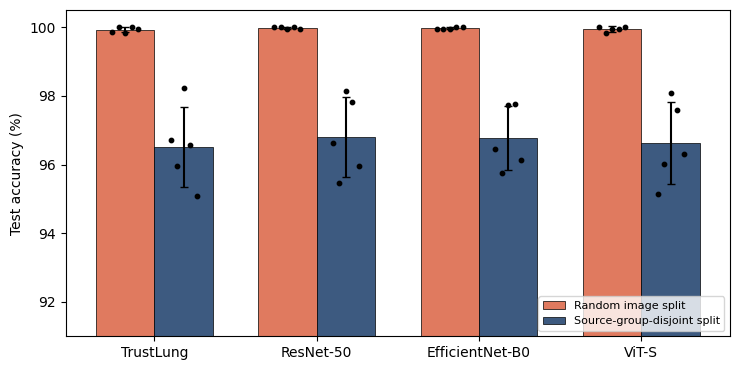

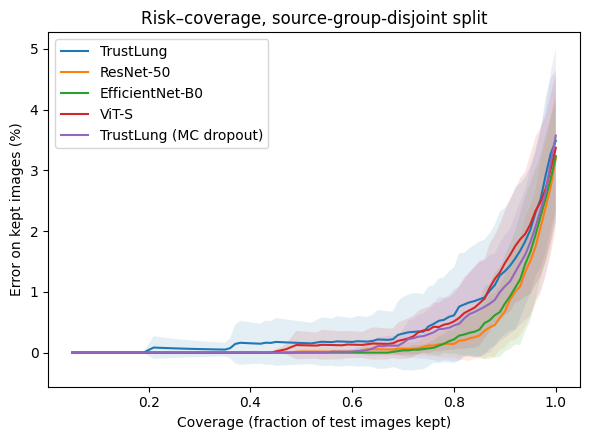


All tables and figures are in /kaggle/working/rev


In [8]:
# (wrapped in try/except so an error here does not stop 'Save & Run All')
try:
    # =============================================================================
    # CELL 6 — ALL TABLES + FIGURES FOR THE REVISION  (CPU only; reads saved .npz files)
    # Needs cell 4 (metrics). Set OUT/SEEDS here if you run it in a fresh session.
    # =============================================================================
    import os, glob, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
    from scipy import stats
    from sklearn.metrics import f1_score, cohen_kappa_score, roc_auc_score
    warnings.filterwarnings("ignore", category=RuntimeWarning)
    # OUT = "/kaggle/working/rev"; SEEDS = [42, 123, 456, 789, 1024]
    BASE = ["resnet50", "effb0", "vit_s"]; ABL = ["no_global", "no_local", "concat", "no_hier", "softmax"]
    NM = {"trustlung": "TrustLung", "resnet50": "ResNet-50", "effb0": "EfficientNet-B0", "vit_s": "ViT-S",
          **{f"tl_{a}": f"TrustLung − {a}" for a in ABL}, "tl_mcd": "TrustLung (MC dropout)"}
    tag = lambda m, p, s, i=None: f"{m}_{p}_split{s}_init{s if i is None else i}"
    have = lambda t: os.path.exists(f"{OUT}/runs/{t}.npz")
    L = lambda t: np.load(f"{OUT}/runs/{t}.npz", allow_pickle=True)
    msd = lambda x, k=1, d=4: f"{np.nanmean(x)*k:.{d}f} ± {np.nanstd(x, ddof=1)*k:.{d}f}" if len(x) > 1 else f"{np.nanmean(x)*k:.{d}f}"
    pct = lambda x: msd(x, 100, 2)
    def paired(a, b):                         # a, b: dict seed -> value ; returns mean diff, CI, p, n
        c = sorted(set(a) & set(b)); d = np.array([a[s] - b[s] for s in c])
        if len(d) < 2: return np.nan, (np.nan, np.nan), np.nan, len(d)
        ci = stats.t.interval(.95, len(d)-1, loc=d.mean(), scale=stats.sem(d)) if d.std() > 0 else (d.mean(), d.mean())
        return d.mean(), ci, stats.ttest_rel([a[s] for s in c], [b[s] for s in c]).pvalue, len(d)
    def save(df, fn): df.to_csv(f"{OUT}/{fn}", index=False); print(f"\n=== {fn} ===\n" + df.to_string(index=False))

    # ---------- per-run metrics (image level + group level + cluster-bootstrap CI) ----------
    rows = []
    for m in ["trustlung"] + BASE + [f"tl_{a}" for a in ABL] + ["tl_mcd"]:
        for p in ("LEAKY", "HONEST"):
            for s in SEEDS:
                if not have(tag(m, p, s)): continue
                r = L(tag(m, p, s)); P, U, y, g = r["test_prob"], r["test_unc"], r["test_y"], r["test_group"]
                pred = P.argmax(1); err = (pred != y).astype(int); gp, gy = group_level(P, y, g)
                ci = cluster_boot(lambda p_, y_: (p_.argmax(1) == y_).mean(), P, y, g, B=1000)
                gid = np.arange(len(gy)).astype(str)                       # one row per source group
                gci = cluster_boot(lambda p_, y_: (p_.argmax(1) == y_).mean(), gp, gy, gid, B=1000)
                gf1 = lambda p_, y_: f1_score(y_, p_.argmax(1), average="macro")
                gfci = cluster_boot(gf1, gp, gy, gid, B=1000); fci = cluster_boot(gf1, P, y, g, B=500)
                ts = fit_temperature(r["val_prob"], r["val_y"])(P)
                rows.append(dict(model=m, protocol=p, seed=s, acc=(pred == y).mean(), acc_lo=ci[0], acc_hi=ci[1],
                                 f1=f1_score(y, pred, average="macro"), kappa=cohen_kappa_score(y, pred),
                                 auc=roc_auc_score(np.eye(3)[y], P, average="macro", multi_class="ovr"),
                                 f1_lo=fci[0], f1_hi=fci[1],
                                 group_acc=(gp.argmax(1) == gy).mean(), group_acc_lo=gci[0], group_acc_hi=gci[1],
                                 group_f1=gf1(gp, gy), group_f1_lo=gfci[0], group_f1_hi=gfci[1], group_ece=ece(gp, gy),
                                 n_groups=len(gy), n_groups_wrong=int((gp.argmax(1) != gy).sum()), n_errors=int(err.sum()),
                                 ece=ece(P, y), ece_ts=ece(ts, y), nll=nll(P, y), brier=brier(P, y),
                                 err_auroc=err_detect(U, err)[0], err_auroc_maxp=err_detect(1 - P.max(1), err)[0],
                                 aurc=risk_coverage(U, err)[2], params_M=float(r["n_params"])/1e6))
    R = pd.DataFrame(rows); R.to_csv(f"{OUT}/all_runs_per_seed.csv", index=False)
    val = lambda m, p, k: R[(R.model == m) & (R.protocol == p)].set_index("seed")[k].to_dict()

    # ---------- TABLE 1: leakage inflation for every model (R1#2, R1#3, R2) ----------
    t1 = []
    for m in ["trustlung"] + BASE:
        for p in ("LEAKY", "HONEST"):
            d = R[(R.model == m) & (R.protocol == p)]
            if len(d): t1.append({"Model": NM[m], "Split": p, "n": len(d), "Params (M)": round(d.params_M.iloc[0], 2),
                                  "Acc (%)": pct(d.acc), "Macro-F1 (%)": pct(d.f1), "AUC (%)": pct(d.auc),
                                  "Image acc 95% cluster-CI (pp, mean of seeds)": f"[{d.acc_lo.mean()*100:.2f}, {d.acc_hi.mean()*100:.2f}]",
                                  "Group-level acc (%)": pct(d.group_acc), "Group acc 95% CI (pp)": f"[{d.group_acc_lo.mean()*100:.2f}, {d.group_acc_hi.mean()*100:.2f}]",
                                  "Group-level F1 (%)": pct(d.group_f1), "Group F1 95% CI": f"[{d.group_f1_lo.mean()*100:.2f}, {d.group_f1_hi.mean()*100:.2f}]",
                                  "Groups wrong / total": f"{d.n_groups_wrong.mean():.1f} / {d.n_groups.mean():.0f}", "n test groups": int(d.n_groups.mean())})
    save(pd.DataFrame(t1), "table1_leaky_vs_honest.csv")
    print("Image-level CIs: cluster bootstrap over source groups. Group-level: one prediction per source group (mean of its images), bootstrap over groups.")
    print("NOTE: LEAKY test groups also appear in LEAKY training, so LEAKY group-level numbers are shown only for completeness.")
    t1b = []
    for m in ["trustlung"] + BASE:
        md, ci, pv, n = paired(val(m, "LEAKY", "acc"), val(m, "HONEST", "acc"))
        la, ho = val(m, "LEAKY", "acc"), val(m, "HONEST", "acc")
        welch = stats.ttest_ind(list(la.values()), list(ho.values()), equal_var=False).pvalue if n > 1 else np.nan
        if n: t1b.append({"Model": NM[m], "Inflation (pp)": f"{md*100:.2f}", "95% CI (pp)": f"[{ci[0]*100:.2f}, {ci[1]*100:.2f}]",
                          "t-test paired by seed p": f"{pv:.3g}", "Welch (unpaired) p": f"{welch:.3g}", "n seeds": n})
    save(pd.DataFrame(t1b), "table1b_inflation_paired.csv")
    print("Unit of analysis = one training run (n = 5). Pairs share the seed (same random state for split sampling and"
          " initialisation); they are NOT evaluated on the same test images, because the two protocols draw different"
          " test sets. Welch p is shown as a sensitivity check that does not assume pairing.")

    # ---------- TABLE 2: TrustLung vs baselines on HONEST, paired by seed (R1#6) ----------
    t2 = []
    for b in BASE:
        for k, lab in [("acc", "Accuracy"), ("f1", "Macro-F1"), ("ece", "ECE raw"), ("ece_ts", "ECE after TS"),
                       ("nll", "NLL"), ("err_auroc", "Error-detection AUROC"), ("aurc", "AURC")]:
            md, ci, pv, n = paired(val("trustlung", "HONEST", k), val(b, "HONEST", k))
            if n: t2.append({"vs": NM[b], "Metric": lab, "TrustLung − baseline": f"{md:.4f}", "95% CI": f"[{ci[0]:.4f}, {ci[1]:.4f}]", "p": f"{pv:.3g}", "n": n})
    save(pd.DataFrame(t2), "table2_trustlung_vs_baselines.csv")

    # ---------- TABLE 3: ablation, HONEST, paired vs full (R1#6) ----------
    t3 = []
    for m in ["trustlung"] + [f"tl_{a}" for a in ABL]:
        d = R[(R.model == m) & (R.protocol == "HONEST")]
        if not len(d): continue
        md, ci, pv, n = paired(val(m, "HONEST", "acc"), val("trustlung", "HONEST", "acc")) if m != "trustlung" else (0, (0, 0), np.nan, len(d))
        t3.append({"Variant": NM[m], "n": len(d), "Acc (%)": pct(d.acc), "Macro-F1 (%)": pct(d.f1), "ECE raw": msd(d.ece),
                   "Err-AUROC": msd(d.err_auroc, 1, 3), "Δacc vs full (pp)": f"{md*100:+.2f}", "95% CI": f"[{ci[0]*100:+.2f}, {ci[1]*100:+.2f}]", "p": f"{pv:.3g}"})
    save(pd.DataFrame(t3), "table3_ablation.csv")

    # ---------- TABLE 4: calibration methods (R1#5, R2) ----------
    t4 = []
        for s in SEEDS:
            if not have(tag(m, "HONEST", s)): continue
            r = L(tag(m, "HONEST", s)); pv_, yv, pt, yt, gt = r["val_prob"], r["val_y"], r["test_prob"], r["test_y"], r["test_group"]
            cal = {"Raw": lambda p: p, "Temperature": fit_temperature(pv_, yv), "Vector": fit_vector(pv_, yv), "Dirichlet": fit_dirichlet(pv_, yv)}
            mo, _, mo_t = mocpo_fit(pv_, yv); cal["MOCPO (temperatures only)"] = mo_t
            for meth in list(cal) + ["MOCPO (full, with class offsets)"]:
                if meth.startswith("MOCPO (full"): q, pred = mo(pt)                 # offsets change the decision
                else: q = cal[meth](pt); pred = q.argmax(1)
                ci = cluster_boot(lambda p_, y_, pr_: ece(p_, y_, pred=pr_), q, yt, gt, B=500, extra=[pred])
                t4.append(dict(model=m, seed=s, method=meth, acc=(pred == yt).mean(), ECE=ece(q, yt, pred=pred), ECE_lo=ci[0], ECE_hi=ci[1],
                               adaECE=ada_ece(q, yt, pred=pred), cwECE=cw_ece(q, yt), NLL=nll(q, yt), Brier=brier(q, yt)))
    T4 = pd.DataFrame(t4); T4.to_csv(f"{OUT}/table4_calibration_per_seed.csv", index=False)
    mets = ["acc", "ECE", "adaECE", "cwECE", "NLL", "Brier"]
    print("ECE for the full MOCPO uses its own (offset-shifted) decision: confidence = p[decision], correct = decision == label")
    t4s = T4.groupby(["model", "method"], sort=False)[mets].agg(lambda x: msd(x)).reset_index(); t4s["model"] = t4s.model.map(NM)
    save(t4s, "table4_calibration_summary.csv")
    raw = T4[(T4.model == "trustlung") & (T4.method == "Raw")].set_index("seed")
    for meth in ("Temperature", "Vector", "Dirichlet", "MOCPO (temperatures only)", "MOCPO (full, with class offsets)"):
        d = T4[(T4.model == "trustlung") & (T4.method == meth)].set_index("seed")
        if len(d) > 1: print(f"TrustLung {meth:32s} vs Raw: ECE p={stats.ttest_rel(d.ECE, raw.ECE).pvalue:.3g} | NLL p={stats.ttest_rel(d.NLL, raw.NLL).pvalue:.3g} | ECE lower in {(d.ECE < raw.ECE).sum()}/{len(d)} seeds")

    # ---------- TABLE 5: uncertainty / selective prediction, HONEST (R1#4, R2) ----------
    t5, curves = [], {}
    for m in ["trustlung"] + BASE + ["tl_mcd"]:
        for s in SEEDS:
            if not have(tag(m, "HONEST", s)): continue
            r = L(tag(m, "HONEST", s)); P, U, y, g = r["test_prob"], r["test_unc"], r["test_y"], r["test_group"]
            e1 = (P.argmax(1) != y).astype(int)
            scores = {"own": (U, e1), "1−maxprob": (1 - P.max(1), e1), "entropy": (entropy(P), e1)}
            if "test_prob_mc" in r.files:                     # MC dropout: errors of the MC-averaged prediction
                emc = (r["test_prob_mc"].argmax(1) != y).astype(int)
                scores.update({"MC entropy": (r["test_mc_entropy"], emc), "MC mutual info": (r["test_mc_mi"], emc)})
            for sc_name, (sc, err) in scores.items():
                au, apr = err_detect(sc, err); cov, risk, aurc = risk_coverage(sc, err)
                ci = cluster_boot(lambda a, b: err_detect(a, b)[0], sc, err, g, B=500)
                t5.append(dict(model=m, seed=s, score=sc_name, AUROC=au, AUROC_lo=ci[0], AUROC_hi=ci[1], AUPRC=apr, AURC=aurc,
                               **{f"acc@{int(c*100)}": acc_at_coverage(sc, err, c) for c in (.9, .8, .7)},
                               acc=1 - err.mean(), MW_p=stats.mannwhitneyu(sc[err == 1], sc[err == 0], alternative="greater").pvalue if 0 < err.sum() < len(err) else np.nan))
                if sc_name == "own": curves.setdefault(m, []).append((cov, risk))
        # ---------- variance sources + deep ensemble (R1#4, R1#8) ----------
    s0 = SEEDS[0]
    ri = [tag("trustlung", "HONEST", s0, i) for i in SEEDS]; rs = [tag("trustlung", "HONEST", s, s0) for s in SEEDS]
    if all(map(have, ri + rs)):
        A = lambda t: (L(t)["test_prob"].argmax(1) == L(t)["test_y"]).mean()
        print(f"\nVARIANCE  init only (split fixed): acc {pct([A(t) for t in ri])} | split only (init fixed): acc {pct([A(t) for t in rs])}")
        runs = [L(t) for t in ri]; y = runs[0]["test_y"]
        assert all((r["test_file"] == runs[0]["test_file"]).all() for r in runs)
        Pm = np.stack([r["test_prob"] for r in runs]); pe = Pm.mean(0); err = (pe.argmax(1) != y).astype(int)
        mi = entropy(pe) - np.mean([entropy(q) for q in Pm], 0); e0 = (runs[0]["test_prob"].argmax(1) != y).astype(int)
        print(f"DEEP ENSEMBLE (5 inits): acc {(pe.argmax(1) == y).mean():.4f} | ECE {ece(pe, y):.4f} | err-AUROC entropy "
              f"{err_detect(entropy(pe), err)[0]:.3f}, mutual info {err_detect(mi, err)[0]:.3f} | single model evidential "
              f"{err_detect(runs[0]['test_unc'], e0)[0]:.3f}")

    # ---------- TABLE 6: shift, OOD, EXTERNAL (R1#4, R1#7) ----------
    t6 = []
    for m in ["trustlung"] + BASE:
        for s in SEEDS:
            fn = f"{OUT}/ext/{tag(m, 'HONEST', s)}.npz"
            if not os.path.exists(fn): continue
            e = np.load(fn, allow_pickle=True); r = L(tag(m, "HONEST", s)); tsf = fit_temperature(r["val_prob"], r["val_y"])
            row = dict(model=m, seed=s)
            for sh in ("none", "blur", "jpeg30", "stain"):
                p, y = e[f"{sh}_prob"], e[f"{sh}_y"]; row[f"acc_{sh}"] = (p.argmax(1) == y).mean(); row[f"ece_{sh}"] = ece(p, y)
            lab = np.r_[np.zeros(len(e["none_unc"])), np.ones(len(e["ood_unc"]))]
            row["OOD_AUROC_colon"] = roc_auc_score(lab, np.r_[e["none_unc"], e["ood_unc"]])
            ye, pat = e["ext_y"], e["ext_patient"]
            for pk in ("crop", "resize"):
                p, u = e[f"ext_{pk}_prob"], e[f"ext_{pk}_unc"]; err = (p.argmax(1) != ye).astype(int)
                row[f"ext_{pk}_acc"] = 1 - err.mean(); row[f"ext_{pk}_f1"] = f1_score(ye, p.argmax(1), average="macro")
                row[f"ext_{pk}_bal_acc"] = np.mean([(p.argmax(1)[ye == k] == k).mean() for k in range(3)])
                ci = cluster_boot(lambda a, b: (a.argmax(1) == b).mean(), p, ye, pat, B=1000) if pd.Series(pat).nunique() > 5 else (np.nan, np.nan)
                row[f"ext_{pk}_acc_lo"], row[f"ext_{pk}_acc_hi"] = ci
                row[f"ext_{pk}_ece"], row[f"ext_{pk}_ece_ts"] = ece(p, ye), ece(tsf(p), ye)
                row[f"ext_{pk}_err_auroc"] = err_detect(u, err)[0]
                lab = np.r_[np.zeros(len(e["none_unc"])), np.ones(len(u))]
                row[f"ext_{pk}_shift_auroc"] = roc_auc_score(lab, np.r_[e["none_unc"], u])
                row[f"ext_{pk}_pred_share"] = np.bincount(p.argmax(1), minlength=3) / len(p)
            row["ext_majority_class_acc"] = np.bincount(ye).max() / len(ye)
            t6.append(row)
    if t6:
        T6 = pd.DataFrame(t6); T6.to_csv(f"{OUT}/table6_shift_external_per_seed.csv", index=False)
        keys = ["acc_none", "acc_blur", "acc_jpeg30", "acc_stain", "OOD_AUROC_colon", "ext_crop_acc", "ext_crop_bal_acc", "ext_crop_f1",
                "ext_crop_ece", "ext_crop_ece_ts", "ext_crop_err_auroc", "ext_crop_shift_auroc", "ext_resize_acc", "ext_resize_bal_acc",
                "ext_resize_shift_auroc", "ext_majority_class_acc"]
        t6s = T6.groupby("model", sort=False)[keys].agg(lambda x: msd(x, 1, 3)).T; t6s.columns = [NM[c] for c in t6s.columns]
        t6s.to_csv(f"{OUT}/table6_shift_external_summary.csv"); print("\n=== table6_shift_external_summary.csv ===\n" + t6s.to_string())
        for m in T6.model.unique():
            print(f"{NM[m]}: share of external images predicted as Benign/ACA/SCC (crop):",
                  np.round(np.mean(np.stack(T6[T6.model == m].ext_crop_pred_share.values), 0), 3))
        for b in BASE:
            for k in ("ext_crop_acc", "ext_crop_shift_auroc", "OOD_AUROC_colon"):
                a_ = T6[T6.model == "trustlung"].set_index("seed")[k].to_dict(); b_ = T6[T6.model == b].set_index("seed")[k].to_dict()
                md, ci, pv, n = paired(a_, b_)
                if n > 1: print(f"TrustLung − {NM[b]:15s} {k:22s} {md:+.3f}  p={pv:.3g}  (n={n})")

    # ---------- FIGURES ----------
    if len(R):
        ms = [m for m in ["trustlung"] + BASE if (R.model == m).any()]; w = .36
        fig, ax = plt.subplots(figsize=(7.5, 3.8))
        for k, (p, col) in enumerate((("LEAKY", "#e07a5f"), ("HONEST", "#3d5a80"))):
            for i, m in enumerate(ms):
                a = R[(R.model == m) & (R.protocol == p)].acc*100
                if not len(a): continue
                x0 = i + (k-.5)*w; ax.bar(x0, a.mean(), w, yerr=a.std(ddof=1) if len(a) > 1 else 0, capsize=3, color=col,
                                           edgecolor="k", lw=.5, label=("Random image split" if p == "LEAKY" else "Source-group-disjoint split") if i == 0 else None)
                ax.scatter(np.full(len(a), x0) + np.linspace(-.08, .08, len(a)), a, s=10, color="k", zorder=3)
        ax.set_xticks(range(len(ms))); ax.set_xticklabels([NM[m] for m in ms]); ax.set_ylabel("Test accuracy (%)")
        ax.set_ylim(max(80, np.floor(R.acc.min()*100) - 2), 100.5); ax.legend(loc="lower right", fontsize=8)
        plt.tight_layout(); plt.savefig(f"{OUT}/fig_leaky_vs_honest.png", dpi=300); plt.show()
    if curves:
        plt.figure(figsize=(6, 4.5)); grid = np.linspace(.05, 1, 96)
        for m, cs in curves.items():
            Rr = np.array([np.interp(grid, c, r) for c, r in cs]); mu = Rr.mean(0); sd = Rr.std(0, ddof=1) if len(Rr) > 1 else 0*mu
            plt.plot(grid, mu*100, label=NM[m]); plt.fill_between(grid, (mu-sd)*100, (mu+sd)*100, alpha=.12)
        plt.xlabel("Coverage (fraction of test images kept)"); plt.ylabel("Error on kept images (%)")
        plt.title("Risk–coverage, source-group-disjoint split"); plt.legend(); plt.tight_layout()
        plt.savefig(f"{OUT}/fig_risk_coverage.png", dpi=300); plt.show()
    print("\nAll tables and figures are in", OUT)

except Exception as _e:
    import traceback; traceback.print_exc()
    print('>>> CELL 6 (tables) FAILED - the notebook continues; send me the error above')


In [9]:
# (wrapped in try/except so an error here does not stop 'Save & Run All')
try:
    # =============================================================================
    # CELL 6b — SENSITIVITY: drop test images that have a near-duplicate in TRAIN  (R1#1)
    # Uses the pHash table H from cell 2 and the saved runs.
    # =============================================================================
    rows = []
    for s in SEEDS:
        d = make_split("HONEST", s)
        tr, te = np.where(d.split == "train")[0], np.where(d.split == "test")[0]
        base_tr = H[tr, 0]
        flag = {DF.filename[i]: int(POP[np.bitwise_xor(H[i][:, None, :], base_tr[None])].sum(-1).min()) <= 6 for i in te}
        for m in ["trustlung", "resnet50", "effb0", "vit_s"]:
            fn = f"{OUT}/runs/{tag_of(m, 'HONEST', s, s)}.npz"
            if not os.path.exists(fn): continue
            r = np.load(fn, allow_pickle=True); ok = r["test_prob"].argmax(1) == r["test_y"]
            keep = np.array([not flag[f] for f in r["test_file"]])
            rows.append(dict(model=m, seed=s, n_test=len(ok), n_flagged=int((~keep).sum()),
                             acc_all=ok.mean(), acc_clean=ok[keep].mean()))
    S7 = pd.DataFrame(rows); S7.to_csv(f"{OUT}/table7_duplicate_sensitivity.csv", index=False)
    print(S7.groupby("model", sort=False)[["n_flagged", "acc_all", "acc_clean"]].mean().round(4).to_string())
    print("If acc_clean ~= acc_all, residual cross-group duplicates do not affect the results.")

except Exception as _e:
    import traceback; traceback.print_exc()
    print('>>> CELL 6b (sensitivity) FAILED - the notebook continues; send me the error above')


           n_flagged  acc_all  acc_clean
model                                   
trustlung        1.2   0.9651     0.9651
resnet50         1.2   0.9680     0.9680
effb0            1.2   0.9677     0.9676
vit_s            1.2   0.9663     0.9663
If acc_clean ~= acc_all, residual cross-group duplicates do not affect the results.


In [10]:
# =============================================================================
# CELL 7 — REPRODUCIBILITY PACKAGE  (R1#8, editor's Data Availability Statement)
# Builds /kaggle/working/revision_release.zip with:
#   code/      the code of every cell run in this session + environment (pip freeze)
#   config/    run_config.json (all settings) + one JSON per run (model, seeds, lr, versions)
#   data/      grouping CSV, split file for EVERY protocol x seed, group audit, cross-group pairs
#   preds/     per-run predictions (.npz: probabilities, uncertainty, labels, group IDs)
#   results/   all tables (.csv) and figures (.png)
#   checksums.json  SHA-256 of every file in the package + of every model checkpoint
#   README.md  what each folder is and how to reproduce
# Model checkpoints (.pt, ~40 MB each) are NOT zipped; upload rev/runs/*.pt to Zenodo separately
# if you want to share weights (their checksums are in checksums.json).
# =============================================================================
import shutil, subprocess, sys, platform
REL = "/kaggle/working/release"; shutil.rmtree(REL, ignore_errors=True)
for d in ("code", "config", "data", "preds", "results"): os.makedirs(f"{REL}/{d}")

# code: every cell executed in this kernel (IPython keeps them in `In`) + environment
try:
    src = "\n\n# " + "="*70 + "\n".join(f"\n# ---- cell {i} ----\n{c}" for i, c in enumerate(In) if c.strip())
    open(f"{REL}/code/notebook_cells_as_run.py", "w").write(src)
except NameError: print("not in IPython: download the notebook (File > Download) and add it to code/")
open(f"{REL}/code/requirements_freeze.txt", "w").write(subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout)
json.dump(dict(python=platform.python_version(), torch=torch.__version__, timm=timm.__version__,
               cuda=torch.version.cuda, gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
               seeds=SEEDS, img=IMG, batch=BATCH, epochs=EPOCHS, optimizer="AdamW (wd 1e-4), cosine schedule",
               lr={"TrustLung family": 3e-4, **{k: v[1] for k, v in BASELINES.items()}},
               backbones={"TrustLung global": "efficientvit_m3.r224_in1k", "TrustLung local": "starnet_s1",
                          **{k: v[0] for k, v in BASELINES.items()}},
               augmentation="resize 224, random horizontal + vertical flip", model_selection="best validation macro-F1",
               split="70/15/15; LEAKY = image-stratified random; HONEST = source-group-disjoint, class-stratified at group level",
               mc_dropout="p=0.2 before heads, T=30 passes", mocpo_consistent=MOCPO_CONSISTENT,
               calibrators_fitted_on="internal validation split only"),
          open(f"{REL}/config/run_config.json", "w"), indent=1)
for f in glob.glob(f"{OUT}/runs/*.json"): shutil.copy(f, f"{REL}/config/")
shutil.copy(CSV, f"{REL}/data/"); shutil.copytree(f"{OUT}/splits", f"{REL}/data/splits")
for f in ("group_audit.csv", "cross_group_pairs.csv", "lc25000_image_groups_merged.csv"):
    if os.path.exists(f"{OUT}/{f}"): shutil.copy(f"{OUT}/{f}", f"{REL}/data/")
for f in glob.glob(f"{OUT}/runs/*.npz") + glob.glob(f"{OUT}/ext/*.npz"):
    shutil.copy(f, f"{REL}/preds/" + ("ext_" if "/ext/" in f else "") + os.path.basename(f))
for f in glob.glob(f"{OUT}/*.csv") + glob.glob(f"{OUT}/*.png"):
    if os.path.basename(f) not in ("group_audit.csv", "cross_group_pairs.csv", "lc25000_image_groups_merged.csv"): shutil.copy(f, f"{REL}/results/")

open(f"{REL}/README.md", "w").write(f"""# Leakage-aware evaluation on LC25000 (lung) — reproducibility package
* data/   grouping file ({os.path.basename(CSV)}), split files `PROTOCOL_splitSEED.csv` (columns filename, y, group, split)
          for every protocol and seed, group audit (740 groups vs 750 originals), cross-group near-duplicate pairs
* config/ run_config.json (all settings, versions, hardware) and one JSON per training run
* preds/  per-run predictions: test/val probabilities, uncertainty, labels, source-group IDs; ext_* = external/shift tests
* results/ all tables and figures in the paper
* code/   the code as run + pip freeze
* checksums.json  SHA-256 of every file (and of the model checkpoints, shared separately)
Images: LC25000 (Borkowski et al., 2019) and LungHist700 are not redistributed; download them from their sources.
To reproduce: run the notebook on a Kaggle T4 with the two datasets attached and the same seeds ({SEEDS}).
""")
sums = {os.path.relpath(f, REL): sha256(f) for f in glob.glob(f"{REL}/**/*", recursive=True) if os.path.isfile(f)}
sums.update({f"checkpoints/{os.path.basename(f)}": sha256(f) for f in glob.glob(f"{OUT}/runs/*.pt")})
json.dump(sums, open(f"{REL}/checksums.json", "w"), indent=1)
shutil.make_archive("/kaggle/working/revision_release", "zip", REL); shutil.rmtree(REL)   # keep only the zip (fewer output files)
print(f"package: /kaggle/working/revision_release.zip  ({len(sums)} files checksummed)")
print("NEXT (by hand): upload the zip to Zenodo -> get a DOI; push code/ + README to GitHub; put both links in the"
      " Data Availability Statement (paper + submission system, identical text).")


package: /kaggle/working/revision_release.zip  (216 files checksummed)
NEXT (by hand): upload the zip to Zenodo -> get a DOI; push code/ + README to GitHub; put both links in the Data Availability Statement (paper + submission system, identical text).
